# Atropelamentos na cidade de São Paulo (2022–2025): limpeza e análise exploratória

**Fonte:** Infosiga SP / Detran-SP, arquivo `dados_infosiga.zip` baixado da aba *Dados Abertos e Documentos*
(dados atualizados em 19/10/2026; dicionário de dados v1.8).

**Pergunta do projeto:** onde, quando e com quem acontecem os atropelamentos de pedestres em São Paulo, para
orientar intervenções de segurança viária.

**Estrutura do notebook**

1. Configuração e leitura dos dados brutos (direto do zip)
2. Limpeza da base de **sinistros**
3. Limpeza da base de **pessoas**
4. Checagens de consistência (incluindo bater com os números do painel do Infosiga)
5. Análise exploratória dos atropelamentos
6. Exportação das bases tratadas para `data/processed/`
7. Limitações e próximos passos

**Critérios de recorte (decididos antes da limpeza)**

| Critério | Valor | Por quê |
|---|---|---|
| Município | `SAO PAULO` (IBGE 3550308) | Escopo do projeto |
| Período | `ano_sinistro` de 2022 a 2025 | Quatro anos completos mais recentes |
| Tipo de registro | `SINISTRO FATAL` e `SINISTRO NAO FATAL` | É o padrão do painel do Infosiga; `NOTIFICACAO` fica de fora da análise principal |
| Atropelamento | `tp_sinistro_atrop_pedestre == "S"` | Marca qualquer sinistro em que houve atropelamento de pedestre, mesmo que não seja o tipo primário |

## 1. Configuração e leitura

In [1]:
from pathlib import Path
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# Funciona rodando de dentro de notebooks/ ou da raiz do projeto
def achar_raiz(inicio: Path = Path.cwd()) -> Path:
    for p in [inicio, *inicio.parents]:
        if (p / "data" / "raw").is_dir():
            return p
    raise FileNotFoundError("pasta data/raw não encontrada acima de " + str(inicio))
ROOT = achar_raiz()
RAW = ROOT / "data" / "raw"
PROCESSED = ROOT / "data" / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)
ZIP_PATH = RAW / "dados_infosiga.zip"

MUNICIPIO = "SAO PAULO"
ANOS = [2022, 2023, 2024, 2025]
TIPOS_REGISTRO = ["SINISTRO FATAL", "SINISTRO NAO FATAL"]

# Paleta (categórica, validada para daltonismo): azul = não fatal / geral, laranja = fatal
AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.edgecolor": "#bdbcb6", "axes.titleweight": "bold", "axes.titlesize": 12,
    "font.size": 10,
})

with zipfile.ZipFile(ZIP_PATH) as z:
    print(pd.DataFrame([(i.filename, i.compress_size / 1e6, i.file_size / 1e6) for i in z.infolist()],
                       columns=["arquivo", "zip_MB", "csv_MB"]).round(1).to_string(index=False))

                arquivo  zip_MB  csv_MB
  pessoas_2015-2021.csv    19.3   164.0
  pessoas_2022-2024.csv    21.0   175.9
  pessoas_2025-2026.csv     9.3    81.1
sinistros_2015-2021.csv    25.3   142.0
sinistros_2022-2024.csv    27.6   157.9
sinistros_2025-2026.csv    12.9    80.9
 veiculos_2015-2021.csv    10.4    59.5
 veiculos_2022-2024.csv    11.1    63.4
 veiculos_2025-2026.csv     4.4    28.6


**Formato dos CSVs** (verificado na inspeção inicial): codificação **Latin-1**, separador **`;`**, quebra de linha
Windows, latitude/longitude com **vírgula decimal** e `numero_logradouro` com ponto (`110.0`).
Por isso tudo é lido como texto (`dtype=str`) e convertido coluna a coluna, em vez de usar `decimal=","` no
arquivo inteiro.

Só os arquivos `*_2022-2024.csv` e `*_2025-2026.csv` são lidos. O arquivo de 2015–2021 e os de veículos não
entram no escopo.

In [2]:
def ler_do_zip(prefixo: str) -> pd.DataFrame:
    """Lê e concatena os CSVs 2022-2024 e 2025-2026 de um tipo (sinistros / pessoas)."""
    partes = []
    with zipfile.ZipFile(ZIP_PATH) as z:
        for sufixo in ["2022-2024", "2025-2026"]:
            nome = f"{prefixo}_{sufixo}.csv"
            df = pd.read_csv(z.open(nome), sep=";", encoding="latin-1", dtype=str)
            df["arquivo_origem"] = nome
            partes.append(df)
    return pd.concat(partes, ignore_index=True)

sin_raw = ler_do_zip("sinistros")
pes_raw = ler_do_zip("pessoas")
print(f"sinistros brutos: {sin_raw.shape}   pessoas brutas: {pes_raw.shape}")

sinistros brutos: (915390, 51)   pessoas brutas: (1191893, 32)


## 2. Limpeza da base de sinistros

### 2.1 Recorte
Aplicamos os três filtros do escopo e mostramos quantas linhas cada um remove, para o recorte ficar rastreável.

In [3]:
etapas = [("bruto (2022-2026, todo o estado)", len(sin_raw))]
sin = sin_raw.copy()
for col in sin.select_dtypes(include=["object", "string"]):
    sin[col] = sin[col].str.strip()

sin = sin[sin["municipio"] == MUNICIPIO];                      etapas.append(("município = SAO PAULO", len(sin)))
sin = sin[sin["ano_sinistro"].astype(int).isin(ANOS)];          etapas.append(("ano 2022-2025", len(sin)))
print("tipo_registro antes do filtro:", sin["tipo_registro"].value_counts().to_dict())
sin = sin[sin["tipo_registro"].isin(TIPOS_REGISTRO)].copy();   etapas.append(("fatal + não fatal (sem NOTIFICACAO)", len(sin)))

pd.DataFrame(etapas, columns=["etapa", "linhas"]).assign(
    removidas=lambda d: (-d["linhas"].diff()).fillna(0).astype(int))

tipo_registro antes do filtro: {'SINISTRO NAO FATAL': 111005, 'NOTIFICACAO': 64242, 'SINISTRO FATAL': 3773}


,etapa,linhas,removidas
0,"bruto (2022-2026, todo o estado)",915390,0
1,município = SAO PAULO,212311,703079
2,ano 2022-2025,179020,33291
3,fatal + não fatal (sem NOTIFICACAO),114778,64242


### 2.2 Tipos de dados e valores ausentes

Decisões de limpeza (todas baseadas no dicionário v1.8):

- **`NAO DISPONIVEL` vira `NaN`** em colunas de texto: no dicionário ele significa "informação não registrada",
  ou seja, é um ausente, não uma categoria real. Manter como categoria distorceria rankings e percentuais.
- **Datas** em `dd/mm/aaaa` → `datetime`; **hora** `HH:MM` → hora inteira (0–23) e um `datetime` completo.
- **Coordenadas** com vírgula decimal → `float`.
- **`qtd_*`** (contagens de veículos e vítimas): vazio significa zero → inteiro com `0`.
- **`tp_sinistro_*`**: `"S"` ou vazio → booleano.
- **`numero_logradouro`** vem como `110.0`; `0` é tratado como ausente.

In [4]:
texto = sin.select_dtypes(include=["object", "string"]).columns
sin[texto] = sin[texto].replace("NAO DISPONIVEL", np.nan)

sin["data_sinistro"] = pd.to_datetime(sin["data_sinistro"], format="%d/%m/%Y", errors="coerce")
hora = pd.to_datetime(sin["hora_sinistro"], format="%H:%M", errors="coerce")
sin["hora"] = hora.dt.hour.astype("Int64")
sin["datahora_sinistro"] = sin["data_sinistro"] + pd.to_timedelta(hora.dt.hour, "h") + pd.to_timedelta(hora.dt.minute, "m")

for c in ["ano_sinistro", "mes_sinistro", "dia_sinistro", "cod_ibge"]:
    sin[c] = sin[c].astype(int)

for c in ["latitude", "longitude"]:
    sin[c] = pd.to_numeric(sin[c].str.replace(",", ".", regex=False), errors="coerce")

num = pd.to_numeric(sin["numero_logradouro"], errors="coerce").replace(0, np.nan)
print("numero_logradouro com casas decimais (truncado):", (num.notna() & (num % 1 != 0)).sum())
sin["numero_logradouro"] = np.floor(num).astype("Int64")

qtd_cols = [c for c in sin.columns if c.startswith("qtd_")]
sin[qtd_cols] = sin[qtd_cols].apply(pd.to_numeric, errors="coerce").fillna(0).astype(int)

tp_cols = [c for c in sin.columns if c.startswith("tp_sinistro_") and c != "tp_sinistro_primario"]
sin[tp_cols] = sin[tp_cols].eq("S")

sin["fatal"] = sin["tipo_registro"].eq("SINISTRO FATAL")
sin["atropelamento"] = sin["tp_sinistro_atrop_pedestre"]

ordem_dias = ["Domingo", "Segunda-feira", "Terça-feira", "Quarta-feira", "Quinta-feira", "Sexta-feira", "Sábado"]
print("dias da semana encontrados:", sorted(sin["dia_da_semana"].dropna().unique()))
sin["dia_da_semana"] = pd.Categorical(sin["dia_da_semana"], categories=ordem_dias, ordered=True)

print("datas inválidas:", sin["data_sinistro"].isna().sum(), "| horas ausentes:", sin["hora"].isna().sum())

numero_logradouro com casas decimais (truncado): 595


dias da semana encontrados: ['Domingo', 'Quarta-feira', 'Quinta-feira', 'Segunda-feira', 'Sexta-feira', 'Sábado', 'Terça-feira']
datas inválidas: 0 | horas ausentes: 132


### 2.3 Validação das coordenadas

Muitas coordenadas vêm de boletins de ocorrência e podem estar ausentes, zeradas ou fora da cidade.
Usamos a caixa que envolve o município de São Paulo (lat −24,01 a −23,35; lon −46,83 a −46,36) como filtro de
sanidade. Pontos fora dela **não são apagados**: só recebem `coord_valida = False` e ficam fora das análises
espaciais.

In [5]:
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = -24.01, -23.35, -46.83, -46.36
sin["coord_valida"] = sin["latitude"].between(LAT_MIN, LAT_MAX) & sin["longitude"].between(LON_MIN, LON_MAX)

resumo_coord = pd.Series({
    "sem coordenada": sin["latitude"].isna().sum(),
    "com coordenada, fora da cidade": (sin["latitude"].notna() & ~sin["coord_valida"]).sum(),
    "coordenada válida": sin["coord_valida"].sum(),
})
print(resumo_coord.to_string())
print(f"\n% válida - todos os sinistros: {sin['coord_valida'].mean():.1%} | "
      f"atropelamentos: {sin.loc[sin['atropelamento'], 'coord_valida'].mean():.1%}")

sem coordenada                      4498
com coordenada, fora da cidade       319
coordenada válida                 109961

% válida - todos os sinistros: 95.8% | atropelamentos: 96.0%


In [6]:
# Ausentes por coluna (só as que têm algum ausente)
aus = sin.isna().mean().sort_values(ascending=False)
aus[aus > 0].mul(100).round(1).to_frame("% ausente").head(15)

,% ausente
tipo_local,23.0
longitude,3.9
latitude,3.9
numero_logradouro,3.0
administracao,1.8
conservacao,1.7
tp_sinistro_primario,1.5
logradouro,1.3
circunscricao,0.7
tipo_via,0.2


In [7]:
assert sin["id_sinistro"].is_unique, "id_sinistro duplicado!"
print("sinistros limpos:", sin.shape, "| id_sinistro único: OK")

sinistros limpos: (114778, 56) | id_sinistro único: OK


## 3. Limpeza da base de pessoas

Uma linha por pessoa envolvida (inclusive ilesos). As colunas-chave para o projeto:
`tipo_de_vitima` (CONDUTOR / PASSAGEIRO / **PEDESTRE**), `idade`, `faixa_etaria_demografica`,
`gravidade_lesao` (ILESO / LEVE / GRAVE / **FATAL**) e `data_obito`.

**Recorte:** mantemos só pessoas cujo `id_sinistro` está na base de sinistros limpa. Assim as duas bases ficam
coerentes entre si (mesmo município, período e tipos de registro).

In [8]:
pes = pes_raw.copy()
for col in pes.select_dtypes(include=["object", "string"]):
    pes[col] = pes[col].str.strip()
texto = pes.select_dtypes(include=["object", "string"]).columns.drop(["arquivo_origem"])
pes[texto] = pes[texto].replace("NAO DISPONIVEL", np.nan)

antes = len(pes)
pes = pes[pes["id_sinistro"].isin(sin["id_sinistro"])].copy()
print(f"pessoas: {antes:,} -> {len(pes):,} após manter só sinistros do recorte")

for c in ["data_sinistro", "data_obito"]:
    pes[c] = pd.to_datetime(pes[c], format="%d/%m/%Y", errors="coerce")
for c in ["ano_sinistro", "mes_sinistro", "dia_sinistro"]:
    pes[c] = pes[c].astype(int)
pes["ano_obito"] = pd.to_numeric(pes["ano_obito"], errors="coerce").astype("Int64")
pes["idade"] = pd.to_numeric(pes["idade"], errors="coerce").astype("Int64")
pes["tempo_sinistro_obito"] = pd.to_numeric(pes["tempo_sinistro_obito"], errors="coerce")

pes["obito"] = pes["gravidade_lesao"].eq("FATAL")
pes["pedestre"] = pes["tipo_de_vitima"].eq("PEDESTRE")
pes["idoso_60mais"] = pes["idade"].ge(60)

# Faixa etária agregada para leitura mais fácil (a demográfica de 5 em 5 anos continua disponível)
bins = [-1, 17, 29, 39, 49, 59, 69, 79, 200]
rotulos = ["0-17", "18-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
pes["faixa_etaria"] = pd.cut(pes["idade"].astype(float), bins=bins, labels=rotulos)

assert pes["id_pessoa"].is_unique
print("tipo_de_vitima:", pes["tipo_de_vitima"].value_counts(dropna=False).to_dict())
print("gravidade_lesao:", pes["gravidade_lesao"].value_counts(dropna=False).to_dict())
print(f"idade ausente: {pes['idade'].isna().mean():.2%} | idade máx: {pes['idade'].max()}")

pessoas: 1,191,893 -> 242,611 após manter só sinistros do recorte


tipo_de_vitima: {'PASSAGEIRO': 99073, 'CONDUTOR': 97334, nan: 26822, 'PEDESTRE': 19382}
gravidade_lesao: {'LEVE': 108413, 'ILESO': 105479, nan: 16334, 'GRAVE': 8497, 'FATAL': 3888}
idade ausente: 0.21% | idade máx: 102


## 4. Checagens de consistência

### 4.1 Bate com o painel do Infosiga?
Na aba *Óbitos* do painel (São Paulo, pedestres, 2022–2025) os números eram **300 / 352 / 376 / 410**.
O painel conta óbitos pelo **ano do óbito**, e não pelo ano do sinistro. Como uma vítima pode morrer até 30 dias
depois, os dois critérios diferem em poucos casos na virada do ano.

Para essa checagem usamos a base de pessoas **sem** o recorte de ano do sinistro, porque um óbito de janeiro/2022
pode vir de um sinistro de dezembro/2021.

In [9]:
ped_obitos_painel = (pes_raw.assign(municipio=pes_raw["municipio"].str.strip())
    .query("municipio == @MUNICIPIO and tipo_de_vitima == 'PEDESTRE' and gravidade_lesao == 'FATAL'")
    ["ano_obito"].astype(int).value_counts().sort_index())
painel = pd.Series({2022: 300, 2023: 352, 2024: 376, 2025: 410})
check = pd.DataFrame({"painel_infosiga": painel,
                      "base_por_ano_obito": ped_obitos_painel.reindex(ANOS),
                      "base_por_ano_sinistro": pes[pes["pedestre"] & pes["obito"]]["ano_sinistro"].value_counts().reindex(ANOS)})
check["confere"] = check["painel_infosiga"].eq(check["base_por_ano_obito"])
check

,painel_infosiga,base_por_ano_obito,base_por_ano_sinistro,confere
2022,300,300,302,True
2023,352,352,353,True
2024,376,376,376,True
2025,410,410,410,True


### 4.2 Pedestres vítimas × sinistros marcados como atropelamento
Esperamos que quase todo pedestre vítima esteja num sinistro com `atropelamento = True`. Se não estiver, é
inconsistência de registro.

In [10]:
ped = pes[pes["pedestre"]].merge(sin[["id_sinistro", "atropelamento"]], on="id_sinistro", how="left")
print(f"pedestres vítimas: {len(ped):,}")
print(f"  em sinistro marcado como atropelamento: {ped['atropelamento'].mean():.1%}")

atrop_ids = sin.loc[sin["atropelamento"], "id_sinistro"]
tem_ped = atrop_ids.isin(pes.loc[pes["pedestre"], "id_sinistro"])
print(f"atropelamentos: {len(atrop_ids):,}")
print(f"  com pelo menos um pedestre na base de pessoas: {tem_ped.mean():.1%}")

pedestres vítimas: 19,382
  em sinistro marcado como atropelamento: 99.8%
atropelamentos: 16,245
  com pelo menos um pedestre na base de pessoas: 88.6%


## 5. Análise exploratória dos atropelamentos

Daqui em diante:
- **`atrop`** = sinistros (fatais e não fatais) com atropelamento de pedestre → unidade é o **sinistro**;
- **`vit_ped`** = pessoas com `tipo_de_vitima = PEDESTRE` → unidade é a **vítima**.

A distinção importa: um atropelamento pode ter mais de uma vítima, e a idade é atributo da pessoa, não do
sinistro.

In [11]:
atrop = sin[sin["atropelamento"]].copy()
vit_ped = pes[pes["pedestre"]].copy()
print(f"atropelamentos (sinistros): {len(atrop):,} | pedestres vítimas: {len(vit_ped):,} | "
      f"pedestres mortos: {vit_ped['obito'].sum():,}")

atropelamentos (sinistros): 16,245 | pedestres vítimas: 19,382 | pedestres mortos: 1,441


### 5.1 Evolução anual

In [12]:
anual = atrop.groupby("ano_sinistro").agg(atropelamentos=("id_sinistro", "size"), fatais=("fatal", "sum"))
anual["letalidade_%"] = (anual["fatais"] / anual["atropelamentos"] * 100).round(2)
anual["peso_no_total_de_sinistros_%"] = (anual["atropelamentos"] / sin.groupby("ano_sinistro").size() * 100).round(1)
anual["obitos_pedestres"] = vit_ped[vit_ped["obito"]].groupby("ano_sinistro").size()
anual

,atropelamentos,fatais,letalidade_%,peso_no_total_de_sinistros_%,obitos_pedestres
ano_sinistro,,,,,
2022,4114,295,7.17,14.5,302
2023,4169,339,8.13,13.7,353
2024,4364,372,8.52,14.7,376
2025,3598,400,11.12,13.7,410


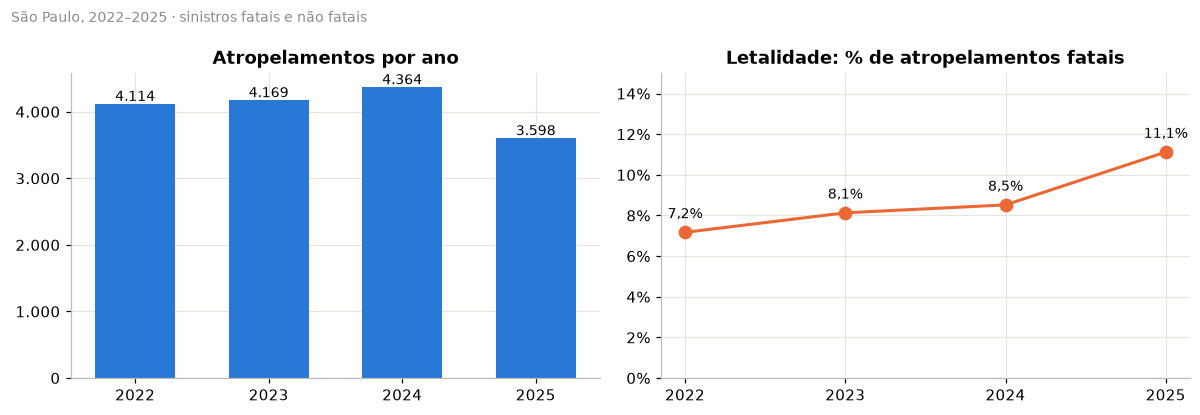

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = anual.index.astype(str)

ax = axes[0]
ax.bar(x, anual["atropelamentos"], color=AZUL, width=0.6)
for xi, v in zip(x, anual["atropelamentos"]):
    ax.text(xi, v, f"{v:,}".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_title("Atropelamentos por ano")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))

ax = axes[1]
ax.plot(x, anual["letalidade_%"], color=LARANJA, lw=2, marker="o", ms=8)
for xi, v in zip(x, anual["letalidade_%"]):
    ax.text(xi, v + 0.7, f"{v:.1f}%".replace(".", ","), ha="center", fontsize=9)
ax.set_ylim(0, anual["letalidade_%"].max() * 1.35)
ax.set_title("Letalidade: % de atropelamentos fatais")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))

fig.suptitle("São Paulo, 2022–2025 · sinistros fatais e não fatais", x=0.01, ha="left", fontsize=9, color=CINZA)
fig.tight_layout()
plt.show()

**Leitura:** os dois gráficos ficam separados de propósito. Quantidade e letalidade estão em escalas diferentes,
e um gráfico com dois eixos sugeriria uma relação que os dados não mostram. Se a letalidade sobe enquanto o
volume se mantém, o atropelamento típico está ficando **mais grave**, e não mais frequente. Vale investigar se
isso vem de velocidade, de mudança no perfil das vítimas (5.3) ou de subnotificação dos casos leves.

**Cuidado com 2025:** a queda de atropelamentos em 2025 vem toda dos **não fatais**, enquanto os fatais
continuam subindo. A base de sinistros não fatais como um todo também cai em 2025. Isso sugere que os registros
não fatais mais recentes ainda estão sendo consolidados (boletins chegam com atraso). Por isso a letalidade de
2025 (11%) provavelmente está **superestimada**. Vale rebaixar o peso desse ano ou refazer a conta numa
atualização futura da base.

### 5.2 Quando acontecem: hora do dia × dia da semana

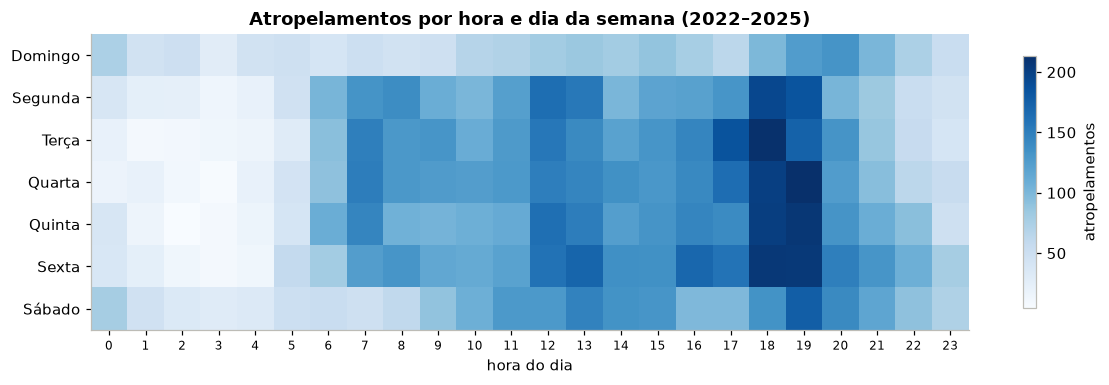

In [14]:
mapa_hd = atrop.pivot_table(index="dia_da_semana", columns="hora", values="id_sinistro",
                            aggfunc="size", observed=False).reindex(columns=range(24)).fillna(0)

fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(mapa_hd.values, aspect="auto", cmap="Blues")
ax.set_xticks(range(24)); ax.set_xticklabels(range(24), fontsize=8)
ax.set_yticks(range(7)); ax.set_yticklabels([d.split("-")[0] for d in mapa_hd.index])
ax.grid(False)
ax.set_xlabel("hora do dia")
ax.set_title("Atropelamentos por hora e dia da semana (2022–2025)")
fig.colorbar(im, ax=ax, label="atropelamentos", shrink=0.85)
fig.tight_layout()
plt.show()

In [15]:
# Letalidade por turno: é à noite que o atropelamento mata mais?
turno = (atrop.groupby("turno").agg(atropelamentos=("id_sinistro", "size"), fatais=("fatal", "sum"))
         .assign(**{"letalidade_%": lambda d: (d["fatais"] / d["atropelamentos"] * 100).round(1),
                    "% dos atropelamentos": lambda d: (d["atropelamentos"] / d["atropelamentos"].sum() * 100).round(1),
                    "% das mortes": lambda d: (d["fatais"] / d["fatais"].sum() * 100).round(1)})
         .reindex(["MADRUGADA", "MANHA", "TARDE", "NOITE"]))
turno

,atropelamentos,fatais,letalidade_%,% dos atropelamentos,% das mortes
turno,,,,,
MADRUGADA,1217,246,20.2,7.5,18.2
MANHA,4365,276,6.3,27.0,20.4
TARDE,5520,320,5.8,34.1,23.6
NOITE,5092,513,10.1,31.4,37.9


**Leitura:** o volume de atropelamentos segue o fluxo de pessoas na rua (picos de manhã e no fim da tarde nos dias
úteis). Já a **letalidade** costuma ser muito maior à noite e de madrugada, com menos visibilidade e mais
velocidade. Compare a coluna "% das mortes" com "% dos atropelamentos": quando a primeira é bem maior que a
segunda, aquele turno pesa nas mortes muito mais do que o volume sugere.

### 5.3 Quem é atropelado: idade das vítimas (destaque 60+)

In [16]:
idade = (vit_ped.groupby("faixa_etaria", observed=False)
         .agg(vitimas=("id_pessoa", "size"), obitos=("obito", "sum")))
idade["letalidade_%"] = (idade["obitos"] / idade["vitimas"] * 100).round(1)
idade["% das vítimas"] = (idade["vitimas"] / idade["vitimas"].sum() * 100).round(1)
idade["% dos óbitos"] = (idade["obitos"] / idade["obitos"].sum() * 100).round(1)
idade

,vitimas,obitos,letalidade_%,% das vítimas,% dos óbitos
faixa_etaria,,,,,
0-17,1968,45,2.3,10.3,3.6
18-29,3624,99,2.7,18.9,7.8
30-39,3319,126,3.8,17.3,10.0
40-49,3409,181,5.3,17.8,14.3
50-59,2712,224,8.3,14.1,17.7
60-69,2176,226,10.4,11.3,17.9
70-79,1317,224,17.0,6.9,17.7
80+,657,138,21.0,3.4,10.9


In [17]:
v60 = vit_ped[vit_ped["idoso_60mais"]]
n_idade = vit_ped["idade"].notna().sum()
print(f"Pedestres 60+: {len(v60) / n_idade:.1%} das vítimas com idade conhecida, "
      f"mas {v60['obito'].sum() / vit_ped.loc[vit_ped['idade'].notna(), 'obito'].sum():.1%} dos óbitos.")
print(f"Letalidade 60+: {v60['obito'].mean():.1%} vs. menores de 60: "
      f"{vit_ped.loc[vit_ped['idade'].lt(60), 'obito'].mean():.1%}")

Pedestres 60+: 21.6% das vítimas com idade conhecida, mas 46.6% dos óbitos.
Letalidade 60+: 14.2% vs. menores de 60: 4.5%


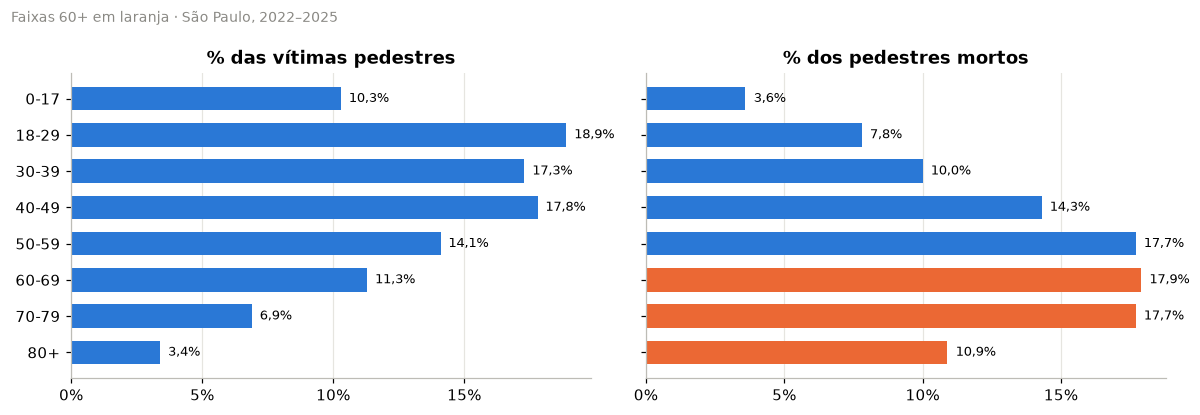

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
y = np.arange(len(idade))
cores = [LARANJA if f in ["60-69", "70-79", "80+"] else AZUL for f in idade.index]

axes[0].barh(y, idade["% das vítimas"], color=AZUL, height=0.65)
axes[0].set_title("% das vítimas pedestres")
axes[1].barh(y, idade["% dos óbitos"], color=cores, height=0.65)
axes[1].set_title("% dos pedestres mortos")
for ax, col in zip(axes, ["% das vítimas", "% dos óbitos"]):
    for yi, v in zip(y, idade[col]):
        ax.text(v + 0.3, yi, f"{v:.1f}%".replace(".", ","), va="center", fontsize=8.5)
    ax.xaxis.set_major_locator(mtick.MultipleLocator(5))
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y); axes[0].set_yticklabels(idade.index); axes[0].invert_yaxis()
fig.suptitle("Faixas 60+ em laranja · São Paulo, 2022–2025", x=0.01, ha="left", fontsize=9, color=CINZA)
fig.tight_layout()
plt.show()

**Leitura:** este é o achado central para um projeto de segurança de pedestres. Os idosos não são a maioria dos
atropelados, mas são a maior fatia dos **mortos**, porque a letalidade cresce muito com a idade (fragilidade
física e menor velocidade de travessia). Isso sustenta medidas como **tempo de travessia maior nos semáforos**
e prioridade para regiões com muitos idosos circulando.

### 5.4 Vias urbanas × estradas e rodovias
No painel não existe a opção "via municipal". As categorias são `VIAS URBANAS`, `ESTRADAS E RODOVIAS` e
(ausente). Trechos de rodovia dentro da cidade (Marginais = SP 015, Fernão Dias = BR 381, Anhanguera,
Bandeirantes, Raposo) são poucos atropelamentos, mas muito letais. Por isso a comparação é feita separadamente.

In [19]:
via = (atrop.groupby("tipo_via", dropna=False).agg(atropelamentos=("id_sinistro", "size"), fatais=("fatal", "sum"))
       .assign(**{"letalidade_%": lambda d: (d["fatais"] / d["atropelamentos"] * 100).round(1),
                  "% das mortes": lambda d: (d["fatais"] / d["fatais"].sum() * 100).round(1)}))
via

,atropelamentos,fatais,letalidade_%,% das mortes
tipo_via,,,,
ESTRADAS E RODOVIAS,417,126,30.2,9.0
VIAS URBANAS,15714,1166,7.4,82.9
NaN,114,114,100.0,8.1


**Leitura:** as rodovias têm poucos atropelamentos, mas cerca de 30% deles são fatais (contra ~7% nas vias
urbanas). Os registros com `tipo_via` ausente são **todos fatais**. Uma hipótese a confirmar com o Detran é que
sejam óbitos que entraram na base por outra fonte, sem os dados completos do boletim de ocorrência. Eles entram
nas contagens de mortes, mas não podem ser classificados por tipo de via.

### 5.5 Onde acontecem: vias com mais atropelamentos
Ranking por **logradouro** (texto livre do boletim). Antes de agrupar, padronizamos espaços e abreviações comuns.

In [20]:
def padroniza_logradouro(s: pd.Series) -> pd.Series:
    s = s.str.upper().str.replace(r"\s+", " ", regex=True).str.strip()
    trocas = {r"VINTE E TRES DE MAIO": "23 DE MAIO", r"VINTE E CINCO DE MARCO": "25 DE MARCO",
              r"^AV\.? ": "AVENIDA ", r"^R\.? ": "RUA ", r"^ESTR\.? ": "ESTRADA ", r"^PCA\.? ": "PRACA "}
    for padrao, novo in trocas.items():
        s = s.str.replace(padrao, novo, regex=True)
    return s

atrop["logradouro_pad"] = padroniza_logradouro(atrop["logradouro"])
sin.loc[atrop.index, "logradouro_pad"] = atrop["logradouro_pad"]

top_vias = (atrop.dropna(subset=["logradouro_pad"]).groupby("logradouro_pad")
            .agg(atropelamentos=("id_sinistro", "size"), fatais=("fatal", "sum"))
            .sort_values(["fatais", "atropelamentos"], ascending=False))
top_vias["letalidade_%"] = (top_vias["fatais"] / top_vias["atropelamentos"] * 100).round(1)
print(f"logradouro ausente em {atrop['logradouro'].isna().mean():.1%} dos atropelamentos")
top_vias.head(20)

logradouro ausente em 1.4% dos atropelamentos


,atropelamentos,fatais,letalidade_%
logradouro_pad,,,
BR 381,91,48,52.7
SP 015 - TIETE,104,28,26.9
SP 330,45,20,44.4
SP 348,30,20,66.7
AVENIDA SAPOPEMBA,165,19,11.5
AVENIDA SENADOR TEOTONIO VILELA,123,17,13.8
AVENIDA INTERLAGOS,87,14,16.1
AVENIDA DO ESTADO,114,13,11.4
AVENIDA INAJAR DE SOUZA,99,13,13.1


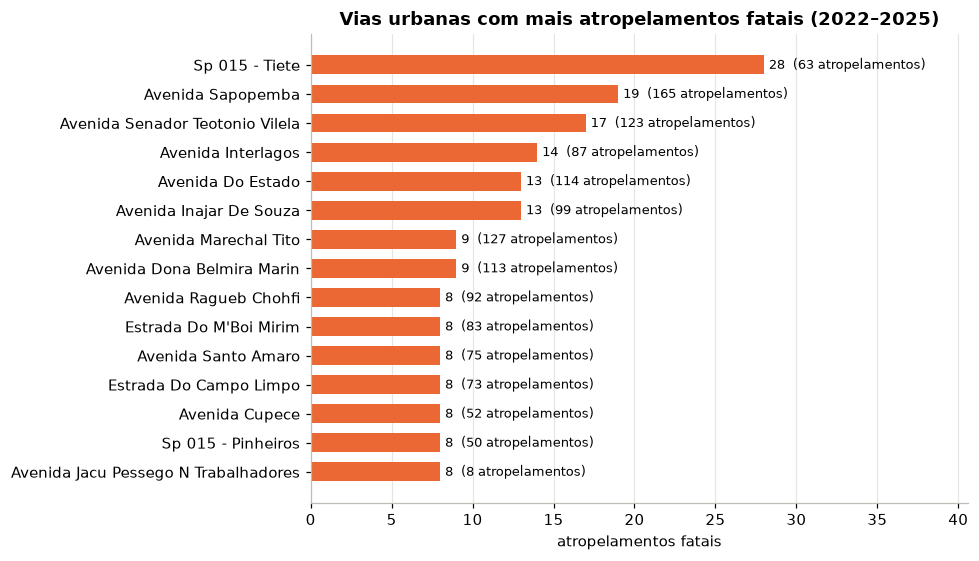

In [21]:
top_vias_urb = (atrop[atrop["tipo_via"].eq("VIAS URBANAS")].dropna(subset=["logradouro_pad"])
                .groupby("logradouro_pad").agg(atropelamentos=("id_sinistro", "size"), fatais=("fatal", "sum"))
                .sort_values(["fatais", "atropelamentos"], ascending=False))
top15 = top_vias_urb.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.2))
ax.barh(top15.index.str.title(), top15["fatais"], color=LARANJA, height=0.65)
for yi, (v, t) in enumerate(zip(top15["fatais"], top15["atropelamentos"])):
    ax.text(v + 0.3, yi, f"{v}  ({t} atropelamentos)", va="center", fontsize=8.5)
ax.set_title("Vias urbanas com mais atropelamentos fatais (2022–2025)")
ax.set_xlabel("atropelamentos fatais")
ax.grid(axis="y", visible=False)
ax.set_xlim(0, top15["fatais"].max() * 1.45)
fig.tight_layout()
plt.show()

**Leitura:** na tabela geral, o topo é ocupado por **rodovias** (BR 381, Marginal Tietê/SP 015, SP 330, SP 348),
com letalidade acima de 25%. O gráfico mostra só os registros classificados como `VIAS URBANAS`. Mesmo assim,
trechos da Marginal (SP 015) aparecem, porque a classificação de `tipo_via` vem do boletim e não é uniforme
para as Marginais. O gráfico mostra só as vias urbanas, onde a prefeitura atua diretamente.
**Atenção:** avenidas longas (Sapopemba, Teotônio Vilela, M'Boi Mirim...) aparecem no topo em parte **por serem
longas**. Por isso o ranking por via é complementado pela análise de pontos críticos em grade
(5.6), que compara áreas de tamanho igual.

### 5.6 Pontos críticos (grade de ~500 m)
Dividimos a cidade em células de 0,005° (cerca de 550 m × 510 m) e contamos atropelamentos por célula. Só entram
sinistros com `coord_valida`. Cada célula recebe o logradouro mais frequente dentro dela, para dar nome ao ponto.

In [22]:
CEL = 0.005
geo = atrop[atrop["coord_valida"]].copy()
geo["cel_lat"] = (np.floor(geo["latitude"] / CEL) * CEL + CEL / 2).round(4)
geo["cel_lon"] = (np.floor(geo["longitude"] / CEL) * CEL + CEL / 2).round(4)

celulas = (geo.groupby(["cel_lat", "cel_lon"])
           .agg(atropelamentos=("id_sinistro", "size"), fatais=("fatal", "sum"),
                via_principal=("logradouro_pad", lambda s: s.mode().iat[0] if s.notna().any() else None))
           .reset_index().sort_values(["atropelamentos", "fatais"], ascending=False))
print(f"atropelamentos com coordenada válida: {len(geo):,} de {len(atrop):,} ({len(geo)/len(atrop):.1%})")
print(f"células com ao menos 1 atropelamento: {len(celulas):,}")
celulas.head(20).reset_index(drop=True)

atropelamentos com coordenada válida: 15,595 de 16,245 (96.0%)
células com ao menos 1 atropelamento: 2,952


,cel_lat,cel_lon,atropelamentos,fatais,via_principal
0,-23.6725,-46.7425,72,3,ACESSO ESTRADA DO M BOI MIRIM
1,-23.5475,-46.6325,61,5,PARQUE DOM PEDRO II
2,-23.5425,-46.6175,57,3,AVENIDA RANGEL PESTANA
3,-23.5475,-46.6375,54,2,AVENIDA 23 DE MAIO
4,-23.5425,-46.6425,47,2,AVENIDA IPIRANGA
5,-23.5425,-46.6375,43,7,AVENIDA RIO BRANCO
6,-23.5425,-46.6325,43,2,RUA 25 DE MARCO
7,-23.5375,-46.6425,41,3,AVENIDA RIO BRANCO
8,-23.5525,-46.6375,40,3,RUA RIACHUELO
9,-23.5375,-46.6325,40,2,AVENIDA PRESTES MAIA


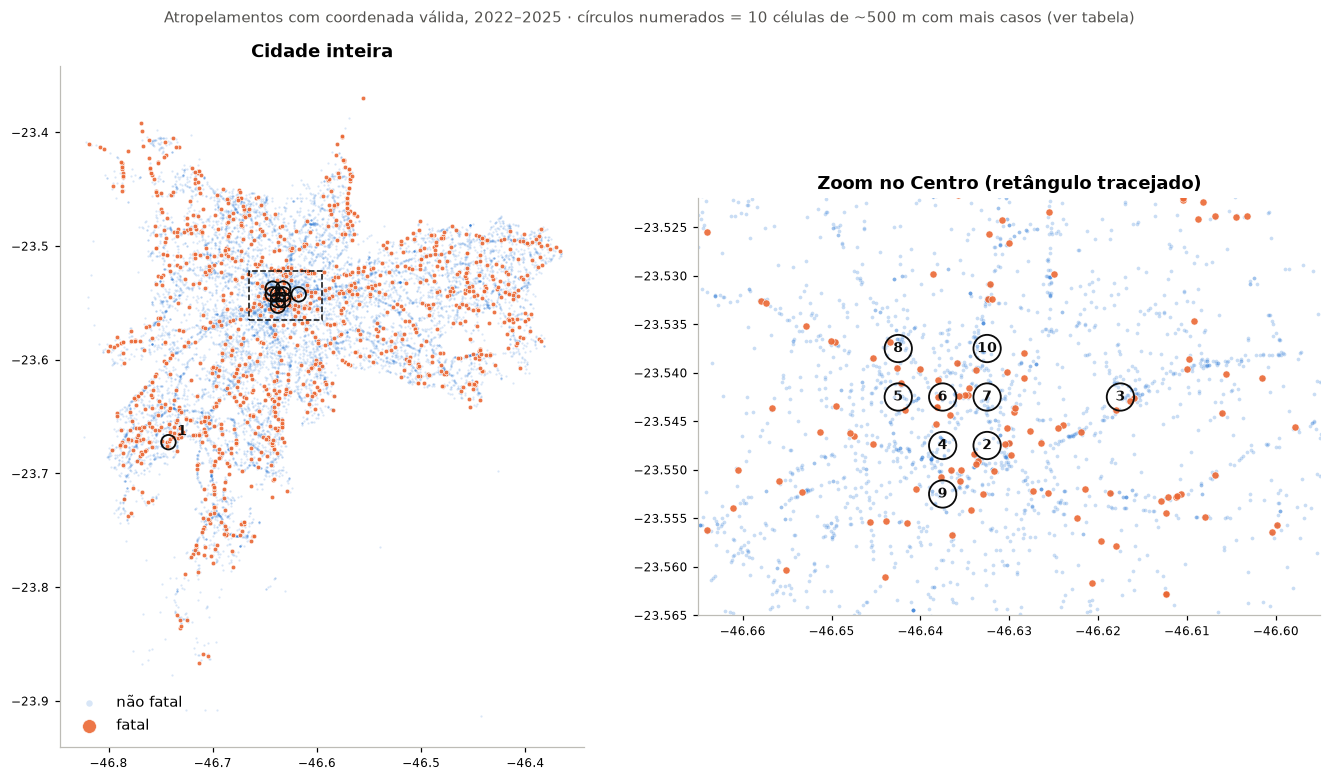

,n,via_principal,atropelamentos,fatais,cel_lat,cel_lon
0,1,ACESSO ESTRADA DO M BOI MIRIM,72,3,-23.6725,-46.7425
1,2,PARQUE DOM PEDRO II,61,5,-23.5475,-46.6325
2,3,AVENIDA RANGEL PESTANA,57,3,-23.5425,-46.6175
3,4,AVENIDA 23 DE MAIO,54,2,-23.5475,-46.6375
4,5,AVENIDA IPIRANGA,47,2,-23.5425,-46.6425
5,6,AVENIDA RIO BRANCO,43,7,-23.5425,-46.6375
6,7,RUA 25 DE MARCO,43,2,-23.5425,-46.6325
7,8,AVENIDA RIO BRANCO,41,3,-23.5375,-46.6425
8,9,RUA RIACHUELO,40,3,-23.5525,-46.6375
9,10,AVENIDA PRESTES MAIA,40,2,-23.5375,-46.6325


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 7.2), gridspec_kw={"width_ratios": [1, 1.05]})
nf, ff = geo[~geo["fatal"]], geo[geo["fatal"]]
top_cel = celulas.head(10).reset_index(drop=True)
CENTRO = dict(lon=(-46.665, -46.595), lat=(-23.565, -23.522))

for k, ax in enumerate(axes):
    zoom = k == 1
    ax.scatter(nf["longitude"], nf["latitude"], s=6 if zoom else 2, color=AZUL, alpha=0.25 if zoom else 0.18,
               linewidths=0, label="não fatal")
    ax.scatter(ff["longitude"], ff["latitude"], s=22 if zoom else 9, color=LARANJA, alpha=0.9, linewidths=0.4,
               edgecolors="white", label="fatal")
    ax.scatter(top_cel["cel_lon"], top_cel["cel_lat"], s=320 if zoom else 90, facecolors="none",
               edgecolors="#0b0b0b", linewidths=1.2)
    for i, r in top_cel.iterrows():
        dentro = CENTRO["lon"][0] < r["cel_lon"] < CENTRO["lon"][1] and CENTRO["lat"][0] < r["cel_lat"] < CENTRO["lat"][1]
        if zoom == dentro:
            ax.annotate(str(i + 1), (r["cel_lon"], r["cel_lat"]), ha="center", va="center", fontsize=9,
                        fontweight="bold", color="#0b0b0b",
                        xytext=(0, 0) if zoom else (9, 7), textcoords="offset points")
    ax.set_aspect(1 / np.cos(np.radians(-23.6)))
    ax.grid(False)
    ax.tick_params(labelsize=8)

axes[0].add_patch(plt.Rectangle((CENTRO["lon"][0], CENTRO["lat"][0]), np.diff(CENTRO["lon"])[0],
                                np.diff(CENTRO["lat"])[0], fill=False, ec="#0b0b0b", lw=1, ls="--"))
axes[0].set_title("Cidade inteira")
axes[0].legend(loc="lower left", markerscale=3, frameon=False)
axes[1].set_xlim(CENTRO["lon"]); axes[1].set_ylim(CENTRO["lat"])
axes[1].set_title("Zoom no Centro (retângulo tracejado)")
fig.suptitle("Atropelamentos com coordenada válida, 2022–2025 · círculos numerados = 10 células de ~500 m "
             "com mais casos (ver tabela)", fontsize=10, color="#52514e")
fig.tight_layout()
plt.show()
top_cel.assign(n=range(1, 11))[["n", "via_principal", "atropelamentos", "fatais", "cel_lat", "cel_lon"]]

**Leitura:** a maior concentração de atropelamentos fica no **Centro expandido** (Parque Dom Pedro II, Rangel
Pestana, 23 de Maio, Ipiranga, Rio Branco, 25 de Março), onde há muita circulação de pedestres. O ponto isolado
com mais casos, porém, é o acesso à Estrada do M'Boi Mirim, na zona sul. As mortes (pontos laranja) ficam mais
espalhadas pela periferia e ao longo dos grandes eixos viários do que os casos não fatais.

### 5.7 Áreas citadas no projeto: Brás e zona sul
Os prints do mapa de calor do Infosiga mostraram concentração no **Brás** (Av. Celso Garcia, Largo da Concórdia,
Av. Rangel Pestana) e na **zona sul** (Av. Santo Amaro, Av. João Dias, Corredor Norte-Sul). Aqui medimos essas
vias com os dados brutos. O Corredor Norte-Sul é formado por várias avenidas, que somamos.

In [24]:
areas = {
    "Brás - Av. Celso Garcia": ["AVENIDA CELSO GARCIA"],
    "Brás - Av. Rangel Pestana": ["AVENIDA RANGEL PESTANA"],
    "Brás - Largo da Concórdia": ["LARGO DA CONCORDIA"],
    "Zona sul - Av. Santo Amaro": ["AVENIDA SANTO AMARO"],
    "Zona sul - Av. João Dias": ["AVENIDA JOAO DIAS"],
    "Corredor Norte-Sul (23 de Maio, Rubem Berta, Moreira Guimarães, Washington Luís, Interlagos)":
        ["AVENIDA 23 DE MAIO", "AVENIDA RUBEM BERTA",
         "AVENIDA MOREIRA GUIMARAES", "AVENIDA WASHINGTON LUIS", "AVENIDA INTERLAGOS"],
}
linhas = []
for area, vias in areas.items():
    m = atrop["logradouro_pad"].isin(vias)
    linhas.append({"área": area, "atropelamentos": m.sum(), "fatais": atrop.loc[m, "fatal"].sum(),
                   "letalidade_%": round(atrop.loc[m, "fatal"].mean() * 100, 1) if m.any() else None})
pd.DataFrame(linhas)

,área,atropelamentos,fatais,letalidade_%
0,Brás - Av. Celso Garcia,111,3,2.7
1,Brás - Av. Rangel Pestana,69,4,5.8
2,Brás - Largo da Concórdia,8,0,0.0
3,Zona sul - Av. Santo Amaro,75,8,10.7
4,Zona sul - Av. João Dias,24,0,0.0
5,"Corredor Norte-Sul (23 de Maio, Rubem Berta, M...",166,22,13.3


Se uma via aparecer com zero casos, confira a grafia real na base antes de concluir algo. O campo é texto livre,
então o nome pode estar escrito de outro jeito:

In [25]:
for termo in ["CELSO GARCIA", "CONCORDIA", "JOAO DIAS", "SANTO AMARO", "MAIO", "RUBEM BERTA"]:
    achados = atrop.loc[atrop["logradouro_pad"].str.contains(termo, na=False), "logradouro_pad"].value_counts().head(4)
    print(f"{termo:>13}: {achados.to_dict()}")

 CELSO GARCIA: {'AVENIDA CELSO GARCIA': 111}
    CONCORDIA: {'LARGO DA CONCORDIA': 8, 'AVENIDA NOSSA SENHORA DA CONCORDIA': 1}
    JOAO DIAS: {'AVENIDA JOAO DIAS': 24, 'RUA JOAO DIAS DE VERGARA': 1, 'PONTE JOAO DIAS': 1, 'TERMINAL JOAO DIAS': 1}
  SANTO AMARO: {'AVENIDA SANTO AMARO': 75, 'ALAMEDA SANTO AMARO': 8, 'RUA SANTO AMARO': 3, 'UPA SANTO AMARO R CARLOS GOMES, 661': 1}
         MAIO: {'AVENIDA 23 DE MAIO': 44, 'RUA TREZE DE MAIO': 6, 'RUA ANTONIO MAIO': 2, 'AVENIDA 23 DE MAIO,': 1}
  RUBEM BERTA: {'AVENIDA RUBEM BERTA': 2}


## 6. Exportação das bases tratadas

- **Parquet** preserva os tipos (datas, booleanos, inteiros com ausentes) e é o formato para continuar no Python.
- **CSV** (`;`, UTF-8 com BOM, vírgula decimal) para abrir no Excel / Power BI sem problema de acentuação.

In [26]:
saidas = {
    "sinistros_sp_2022_2025": sin,
    "atropelamentos_sp_2022_2025": atrop,
    "pessoas_sp_2022_2025": pes,
    "vitimas_pedestres_sp_2022_2025": vit_ped,
    "pontos_criticos_grade500m_sp_2022_2025": celulas,
}
for nome, df in saidas.items():
    df = df.drop(columns=["arquivo_origem"], errors="ignore")
    df.to_parquet(PROCESSED / f"{nome}.parquet", index=False)
    if nome != "sinistros_sp_2022_2025" and nome != "pessoas_sp_2022_2025":
        df.to_csv(PROCESSED / f"{nome}.csv", sep=";", decimal=",", index=False, encoding="utf-8-sig")

pd.DataFrame([(p.name, round(p.stat().st_size / 1e6, 2)) for p in sorted(PROCESSED.iterdir())],
             columns=["arquivo", "MB"])

,arquivo,MB
0,.gitkeep,0.00
1,atropelamentos_sp_2022_2025.csv,6.69
2,atropelamentos_sp_2022_2025.parquet,1.00
3,pessoas_sp_2022_2025.parquet,5.86
4,pontos_criticos_grade500m_sp_2022_2025.csv,0.14
5,pontos_criticos_grade500m_sp_2022_2025.parquet,0.04
6,sinistros_sp_2022_2025.parquet,5.39
7,vitimas_pedestres_sp_2022_2025.csv,4.17
8,vitimas_pedestres_sp_2022_2025.parquet,0.45


## 7. Limitações e próximos passos

**Limitações dos dados**
- **Coordenadas:** parte dos atropelamentos não tem coordenada válida (ver 2.3). As análises espaciais
  subestimam os pontos críticos onde o registro é mais precário.
- **Logradouro é texto livre:** a mesma via pode estar escrita de formas diferentes. A padronização aqui é
  básica (abreviações e espaços).
- **Notificações excluídas:** registros `NOTIFICACAO` (sem vítima confirmada) ficaram fora, seguindo o padrão do
  painel. Isso deixa os números comparáveis aos oficiais, mas omite parte dos eventos.
- **Óbito em até 30 dias:** o critério de sinistro fatal do Infosiga considera óbitos até 30 dias depois.
  Contagens por ano do sinistro e por ano do óbito diferem em poucos casos (ver 4.1).
- **"Atropelamento"** aqui é `tp_sinistro_atrop_pedestre`, e não o tipo primário. Isso inclui atropelamentos
  que ocorreram dentro de um sinistro classificado primeiro como outro tipo (ex.: colisão seguida de
  atropelamento).

**Próximos passos sugeridos**
1. Normalizar as taxas por população (por distrito ou subprefeitura), usando dados do IBGE/SEADE.
2. Cruzar os pontos críticos com a localização de semáforos, faixas de pedestre e equipamentos para idosos.
3. Usar uma grade hexagonal (H3) ou estimativa de densidade (KDE) para refinar os pontos críticos.
4. Testar se a alta da letalidade se mantém controlando por idade e turno (ex.: regressão logística
   `obito ~ faixa_etaria + turno + tipo_via`).